In [9]:
#Image imports
from pathlib import Path

from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

import colorsys

import time
import re
import numpy as np


from transformers import AutoProcessor, AutoModelForMultimodalLM

#Streaming imports
import time
from threading import Thread
from transformers import TextIteratorStreamer

from ultralytics import YOLO

In [10]:
img_path = "../data/pose-1.png"
img = Image.open(img_path)

In [11]:
#bbox / localization
processor = AutoProcessor.from_pretrained("Qwen/Qwen3.5-2B")
model = AutoModelForMultimodalLM.from_pretrained("Qwen/Qwen3.5-2B", device_map="auto")

Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

Some parameters are on the meta device because they were offloaded to the disk.


In [12]:
prompt = """
Detect every MMA fighter in the image.
For each fighter, return a JSON object with:
  "bbox_2d": [x1, y1, x2, y2] (coordinates normalized to 0-1000),
  "label": "fighter",
  "sub_label": species or "" if unknown
Return a JSON array only, with no other text.
"""

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": img},
            {"type": "text", "text": prompt}
        ]
    },
] 

inputs = processor.apply_chat_template(
	messages,
	add_generation_prompt=True,
	tokenize=True,
	return_dict=True,
	return_tensors="pt",
).to(model.device)

In [60]:
streamer = TextIteratorStreamer(
    processor.tokenizer,
    skip_prompt=True,
    skip_special_tokens=True,
)

# keep a place for the tensor generate returns
result = {}

def run():
    result["sequences"] = model.generate(
        **inputs,
        max_new_tokens=1024,
        streamer=streamer,
    )

t0 = time.perf_counter()
thread = Thread(target=run)
thread.start()

for piece in streamer:
    print(piece, end="", flush=True)

thread.join()
T = time.perf_counter() - t0

L_prompt = inputs["input_ids"].shape[-1]
L_out = result["sequences"].shape[-1]
N = L_out - L_prompt

print()
print("N [New tokens] =", N)
print("T [Wall time] =", T)
print("N/T [Throughput] =", N / T, "tok/s")

```json
[
	{"bbox_2d": [272, 220, 452, 952], "label": "MMA fighter", "sub_label": "fighter"},
	{"bbox_2d": [412, 180, 776, 868], "label": "MMA fighter", "sub_label": "fighter"}
]
```

N [New tokens] = 97
T [Wall time] = 269.1589876250073
N/T [Throughput] = 0.3603817983412114 tok/s


In [14]:
dets = [
	{"bbox_2d": [272, 220, 452, 952], "label": "MMA fighter", "sub_label": "fighter"},
	{"bbox_2d": [412, 180, 776, 868], "label": "MMA fighter", "sub_label": "fighter"}
]

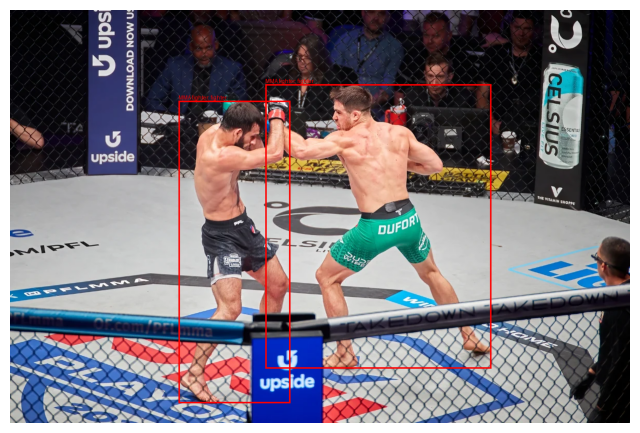

In [15]:
def norm1000_to_pixels(bbox, w, h):
    x1, y1, x2, y2 = bbox
    return [
        int(x1 / 1000 * w),
        int(y1 / 1000 * h),
        int(x2 / 1000 * w),
        int(y2 / 1000 * h),
    ]

img = Image.open(img_path).convert("RGB")
w, h = img.size
vis = img.copy()
draw = ImageDraw.Draw(vis)

for d in dets:
    x1, y1, x2, y2 = norm1000_to_pixels(d["bbox_2d"], w, h)
    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
    sub = d.get("sub_label") or ""
    label = d["label"] if not sub else f'{d["label"]}: {sub}'
    draw.text((x1, max(0, y1 - 12)), label, fill="red")

plt.figure(figsize=(8, 8))
plt.imshow(vis)
plt.axis("off")
plt.show()

stored 2 localizations


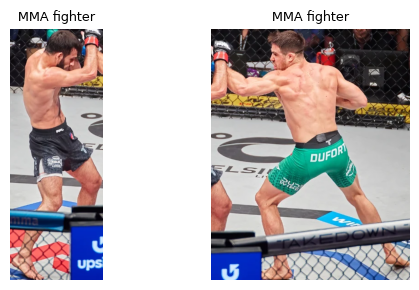

In [16]:
img = Image.open(img_path).convert("RGB")
w, h = img.size

# crop each box → store in a dict
crops = {}
for i, d in enumerate(dets):
    x1, y1, x2, y2 = d["bbox_2d"]
    box = [
        int(x1 / 1000 * w),
        int(y1 / 1000 * h),
        int(x2 / 1000 * w),
        int(y2 / 1000 * h),
    ]
    # clamp + ensure valid box
    x1, y1 = max(0, box[0]), max(0, box[1])
    x2, y2 = min(w, box[2]), min(h, box[3])
    if x2 <= x1 or y2 <= y1:
        continue

    key = f"{i}_{d['label']}"
    crops[key] = {
        "label": d["label"],
        "bbox_2d": d["bbox_2d"],
        "bbox_px": [x1, y1, x2, y2],
        "image": img.crop((x1, y1, x2, y2)),
    }

print(f"stored {len(crops)} localizations")

# plot all crops in a grid
n = len(crops)
cols = min(4, n) if n else 1
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
axes = [axes] if n == 1 else axes.flatten()

for ax, (key, item) in zip(axes, crops.items()):
    ax.imshow(item["image"])
    ax.set_title(item["label"], fontsize=9)
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
pose_model = YOLO("yolo26n-pose.pt")

In [17]:
crops

{'0_MMA fighter': {'label': 'MMA fighter',
  'bbox_2d': [272, 220, 452, 952],
  'bbox_px': [326, 176, 542, 761],
  'image': <PIL.Image.Image image mode=RGB size=216x585>},
 '1_MMA fighter': {'label': 'MMA fighter',
  'bbox_2d': [412, 180, 776, 868],
  'bbox_px': [494, 144, 931, 694],
  'image': <PIL.Image.Image image mode=RGB size=437x550>}}

In [ ]:
# [{label, bbox_px, keypoints, scores}, ...]  — all in ORIGINAL image coords
pose_instances = []

for key, item in crops.items():
    x0, y0, x1, y1 = item["bbox_px"]
    res = pose_model.predict(item["image"], verbose=False)[0]

    if res.keypoints is None or len(res.keypoints) == 0:
        continue

    kxy = res.keypoints.xy.cpu().numpy()
    kconf = (
        res.keypoints.conf.cpu().numpy()
        if res.keypoints.conf is not None
        else np.ones(kxy.shape[:2], dtype=np.float32)
    )

    if len(kxy) == 0:
        continue
    elif len(kxy) == 1:
        idx = 0
    else:
        idx = int(kconf.mean(axis=1).argmax())

    person_xy, person_conf = kxy[idx], kconf[idx]

    kpts_full = person_xy.copy()
    kpts_full[:, 0] += x0
    kpts_full[:, 1] += y0

    pose_instances.append({
        "id": key,
        "label": item["label"],
        "bbox_px": [x0, y0, x1, y1],
        "keypoints": kpts_full.tolist(),
        "keypoint_scores": person_conf.tolist(),
    })

print(f"{len(pose_instances)} posed instances")

2 posed instances


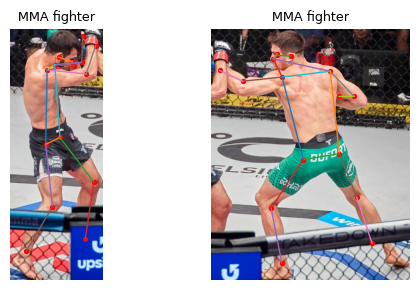

In [45]:
SKELETON = [
    # head
    (0, 1), (0, 2),          # nose → eyes
    (1, 3), (2, 4),          # eyes → ears
    (0, 5), (0, 6),          # nose → shoulders
    # arms
    (5, 7), (7, 9), (6, 8), (8, 10),
    # torso
    (5, 6), (5, 11), (6, 12), (11, 12),
    # legs
    (11, 13), (13, 15), (12, 14), (14, 16),
]

cols = min(4, max(1, len(crops)))
rows = (len(crops) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
axes = np.atleast_1d(axes).ravel()

by_id = {p["id"]: p for p in pose_instances}

for ax, (key, item) in zip(axes, crops.items()):
    ax.imshow(item["image"])

    if key in by_id:
        inst = by_id[key]
        x0, y0, _, _ = inst["bbox_px"]
        pts = np.array(inst["keypoints"])
        scores = np.array(inst["keypoint_scores"])
        pts[:, 0] -= x0
        pts[:, 1] -= y0

        for a, b in SKELETON:
            if scores[a] >= 0.3 and scores[b] >= 0.3:
                ax.plot([pts[a, 0], pts[b, 0]], [pts[a, 1], pts[b, 1]], linewidth=1)
        vis = scores >= 0.3
        ax.scatter(pts[vis, 0], pts[vis, 1], c="r", s=8)

    ax.set_title(item["label"], fontsize=9)
    ax.axis("off")

for ax in axes[len(crops):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

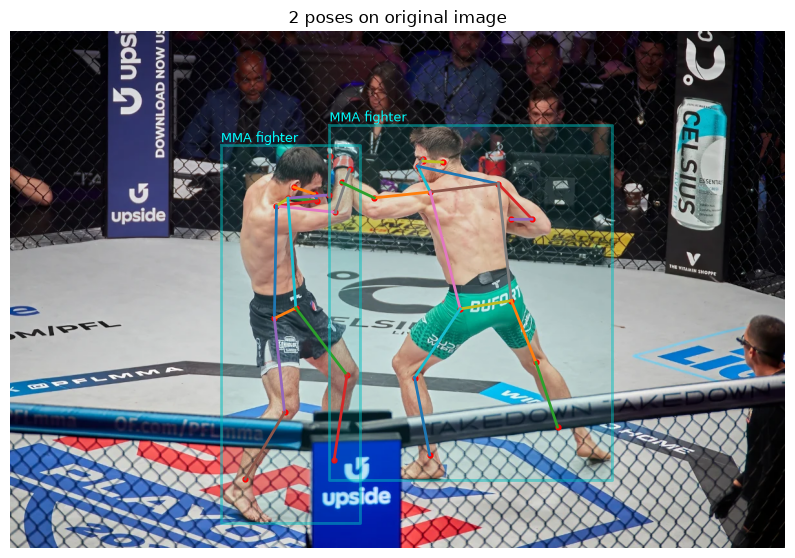

In [59]:
SKELETON = [
    (0, 1), (0, 2), (1, 3), (2, 4), (0, 5), (0, 6),
    (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 6), (5, 11), (6, 12), (11, 12),
    (11, 13), (13, 15), (12, 14), (14, 16),
]

img = Image.open(img_path).convert("RGB")
vis = np.array(img)

plt.figure(figsize=(10, 10))
plt.imshow(vis)

for inst in pose_instances:
    x1, y1, x2, y2 = inst["bbox_px"]
    pts = np.array(inst["keypoints"])
    scores = np.array(inst["keypoint_scores"])

    plt.plot([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], "c-", alpha=0.5, linewidth=2)
    plt.fill([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], "c", alpha=0.1)
    plt.text(x1, max(0, y1 - 5), inst["label"], color="cyan", fontsize=9)

    for a, b in SKELETON:
        if scores[a] >= 0.3 and scores[b] >= 0.3:
            plt.plot([pts[a, 0], pts[b, 0]], [pts[a, 1], pts[b, 1]], linewidth=2)

    vis_k = scores >= 0.3
    plt.scatter(pts[vis_k, 0], pts[vis_k, 1], c="r", s=12)

plt.axis("off")
plt.title(f"{len(pose_instances)} poses on original image")
plt.show()